# Modélisation et suivi MLflow — Scoring crédit "Prêt à dépenser" (2/2)

Ce notebook charge le dataset enrichi (produit par le Notebook 1 `projet6.ipynb`) 
et réalise :
* La comparaison de modèles avec validation croisée
* L'optimisation des hyperparamètres
* L'analyse de feature importance (globale et locale)
* L'optimisation du seuil métier
* Le model registry et le serving MLflow

## 1. Imports

Ce notebook s'appuie sur le dataset enrichi produit par le Notebook 1.

Nous importons ici les packages nécessaires, chargeons les données et redéfinissons les fonctions utilitaires qui seront réutilisées tout au long de l'analyse.

### 1.1. Packages

En plus des librairies classiques (numpy, pandas, scikit-learn), nous utilisons **MLflow** pour le tracking des expérimentations, **LightGBM** et **XGBoost** pour la modélisation, ainsi que **SHAP** et **matplotlib** pour l'interprétabilité.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ML
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, accuracy_score, 
                             recall_score, f1_score, confusion_matrix)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier


# Avertissements
import warnings
warnings.filterwarnings('ignore')

# MLflow
import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature

mlflow.set_tracking_uri("http://127.0.0.1:5000")

### 1.2. Données

Nous chargeons directement les fichiers `.parquet` produits à la fin du Notebook 1, qui contiennent le dataset enrichi de l'ensemble des tables sources agrégées.

In [2]:
app_train = pd.read_parquet('./input/app_train_enriched.parquet')

y = app_train['TARGET']
X = app_train.drop(columns=['TARGET'])

print(f"Dataset enrichi : {X.shape[0]} lignes, {X.shape[1]} features")

Dataset enrichi : 307507 lignes, 1017 features


### 1.3. Fonctions utilitaires

Certaines fonctions crées dans le premier Notebook vont être réutilisées ici, il faut donc les redéfinir.

In [3]:
# Définition de la fonction de coût métier
def calcul_cout_metier(y_true, y_pred, cout_fn=10, cout_fp=1):
    """
    Calcule le coût financier des erreurs du modèle.
    Par défaut, on estime qu'un Faux Négatif (défaut de paiement non détecté) 
    coûte 10 fois plus cher qu'un Faux Positif (client légitime refusé).
    """
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    metier = (fn * cout_fn) + (fp * cout_fp)
    return metier

In [4]:
# Extraction automatique des paramètres
def extract_pipeline_params(pipeline):
    """Extrait les paramètres utiles du pipeline pour MLflow."""
    params = {}
    for name, step in pipeline.named_steps.items():
        step_params = step.get_params()
        for param_name, param_value in step_params.items():
            # Filtre les types compatibles avec MLflow
            if isinstance(param_value, (str, int, float, bool)) or param_value is None:
                params[f"{name}__{param_name}"] = param_value
    return params

In [5]:
# Fonction principale
def train_and_log_model(pipeline, X, y, experiment_name, run_name, tags_dict, step, n_splits=5):
    """
    Entraîne un modèle avec StratifiedKFold et logue tout dans MLflow.
    """
    mlflow.set_experiment(experiment_name)
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    
    # Listes pour stocker les métriques de chaque fold
    auc_scores, accuracy_scores, recall_scores, f1_scores, cout_metier_scores = [], [], [], [], []
    
    with mlflow.start_run(run_name=run_name):
        for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
            # Split
            X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
            y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
            
            # Entraînement
            pipeline.fit(X_train, y_train)
            
            # Prédictions
            y_pred = pipeline.predict(X_val)
            y_pred_proba = pipeline.predict_proba(X_val)[:, 1]
            
            # Métriques du fold
            auc_scores.append(roc_auc_score(y_val, y_pred_proba))
            accuracy_scores.append(accuracy_score(y_val, y_pred))
            recall_scores.append(recall_score(y_val, y_pred))
            f1_scores.append(f1_score(y_val, y_pred))
            cout_metier_scores.append(calcul_cout_metier(y_val, y_pred))

            # Print du fold
            print(f"Fold {fold+1}/{n_splits} - Coût métier : {cout_metier_scores[-1]:.4f}")
        
        # Logging des moyennes ET des écarts-types
        mlflow.log_metric("auc_mean", np.mean(auc_scores))
        mlflow.log_metric("auc_std", np.std(auc_scores))
        mlflow.log_metric("acc_mean", np.mean(accuracy_scores))
        mlflow.log_metric("acc_std", np.std(accuracy_scores))
        mlflow.log_metric("rec_mean", np.mean(recall_scores))
        mlflow.log_metric("rec_std", np.std(recall_scores))
        mlflow.log_metric("f1_mean", np.mean(f1_scores))
        mlflow.log_metric("f1_std", np.std(f1_scores))
        mlflow.log_metric("met_mean", np.mean(cout_metier_scores))
        mlflow.log_metric("met_std", np.std(cout_metier_scores))
        
        # Logging des tags (commentaires, modèle)
        for key, value in tags_dict.items():
            mlflow.set_tag(key, value)
        
        # Ré-entraînement sur l'ensemble des données
        pipeline.fit(X, y)

        # Logging automatique des paramètres du pipeline
        params = extract_pipeline_params(pipeline)
        for key, value in params.items():
            mlflow.log_param(key, value)
        mlflow.log_param("step", step)

        # Sauvegarde du modèle
        signature = infer_signature(X, pipeline.predict(X))
        mlflow.sklearn.log_model(
            sk_model=pipeline,
            artifact_path="model",
            signature=signature,
            registered_model_name="Credit_Scoring_Model"
        )
        
        print(f"Run '{run_name}' terminé — Coût métier : {np.mean(cout_metier_scores):.4f} (±{np.std(cout_metier_scores):.4f})")

## 2. Réentraînement des modèles sélectionnés

### 2.1. Rappel des résultats du Notebook 1

Modèles entraînés sur `application_train` uniquement (avant feature engineering) :
- **LightGBM** : coût métier = 32 882 (champion)
- **XGBoost** : coût métier = 33 706 (challenger)
- **LogReg** : coût métier = 36 740 (baseline)

L'objectif est maintenant de réentraîner ces modèles sur le dataset 
enrichi pour mesurer l'apport du feature engineering.

In [6]:
# --- Tag commun pour identifier cette série ---
common_tags = {
    "features": "enriched_all_tables",
    "statut": "developpement",
    "mlflow.note.content": "Réentraînement sur dataset enrichi (6 tables + feature engineering)."
}

In [7]:
# --- Régression Logistique ---
pipeline_lr = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler()),
    ('classifier', LogisticRegression(C=0.0001, class_weight='balanced', random_state=42))
])
train_and_log_model(pipeline_lr, X, y, 
                    experiment_name="Projet6_Scoring_Credit",
                    run_name="LogReg_enriched",
                    tags_dict={**common_tags, "Type_modele": "baseline"},
                    step=2)

Fold 1/5 - Coût métier : 34665.0000
Fold 2/5 - Coût métier : 34211.0000
Fold 3/5 - Coût métier : 34492.0000
Fold 4/5 - Coût métier : 34326.0000
Fold 5/5 - Coût métier : 34402.0000


2026/03/05 11:41:05 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/03/05 11:41:06 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/03/05 11:41:20 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Registered model 'Credit_Scoring_Model' already exists. Creating a new version of this model...
2026/03/05 11:41:22 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: Credit_Scoring_Model, version 61
Created version '61' of model 'Credit_Sco

Run 'LogReg_enriched' terminé — Coût métier : 34419.2000 (±153.6534)
🏃 View run LogReg_enriched at: http://127.0.0.1:5000/#/experiments/3/runs/575cd339179b4074b262cbfeeea1c190
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


In [8]:
# --- XGBoost ---
from xgboost import XGBClassifier

scale_pos = (y == 0).sum() / (y == 1).sum()
pipeline_xgb = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler()),
    ('classifier', XGBClassifier(
        scale_pos_weight=scale_pos, eval_metric='logloss', random_state=42
    ))
])
train_and_log_model(pipeline_xgb, X, y,
                    experiment_name="Projet6_Scoring_Credit",
                    run_name="XGBoost_enriched",
                    tags_dict={**common_tags, "Type_modele": "challenger"},
                    step=2)

Fold 1/5 - Coût métier : 32019.0000
Fold 2/5 - Coût métier : 30823.0000
Fold 3/5 - Coût métier : 31691.0000
Fold 4/5 - Coût métier : 31168.0000
Fold 5/5 - Coût métier : 31716.0000


2026/03/05 11:55:39 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/03/05 11:55:39 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/03/05 11:55:47 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Registered model 'Credit_Scoring_Model' already exists. Creating a new version of this model...
2026/03/05 11:55:48 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: Credit_Scoring_Model, version 62
Created version '62' of model 'Credit_Sco

Run 'XGBoost_enriched' terminé — Coût métier : 31483.4000 (±428.8760)
🏃 View run XGBoost_enriched at: http://127.0.0.1:5000/#/experiments/3/runs/70ed23be6e2740bf9d4d2dbdc0697b9a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


In [9]:
# --- LightGBM ---
from lightgbm import LGBMClassifier
#
pipeline_lgbm = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler()),
    ('classifier', LGBMClassifier(
        is_unbalance=True, random_state=42, verbose=-1
    ))
])
train_and_log_model(pipeline_lgbm, X, y,
                    experiment_name="Projet6_Scoring_Credit",
                    run_name="LightGBM_enriched",
                    tags_dict={**common_tags, "Type_modele": "champion"},
                    step=2)

Fold 1/5 - Coût métier : 30526.0000
Fold 2/5 - Coût métier : 29676.0000
Fold 3/5 - Coût métier : 30738.0000
Fold 4/5 - Coût métier : 29693.0000
Fold 5/5 - Coût métier : 30771.0000


2026/03/05 12:07:26 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/03/05 12:07:27 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/03/05 12:07:33 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Registered model 'Credit_Scoring_Model' already exists. Creating a new version of this model...
2026/03/05 12:07:34 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: Credit_Scoring_Model, version 63
Created version '63' of model 'Credit_Sco

Run 'LightGBM_enriched' terminé — Coût métier : 30280.8000 (±494.1139)
🏃 View run LightGBM_enriched at: http://127.0.0.1:5000/#/experiments/3/runs/91055240cb1c459dbea92368e5fb271d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


## 3. Feature importance globale

Analyse des features les plus influentes pour chaque modèle :
- **LightGBM / XGBoost** : importance built-in (gain moyen par feature)
- **Logistic Regression** : permutation importance (impact sur le score en permutant chaque feature)

Créons d’abord une fonction d’affichage de la Feature Importance

In [10]:
import os
os.makedirs("./figures", exist_ok=True)

In [11]:
def plot_feature_importance(importances, feature_names, title, top_n=20, filepath=None):
    """
    Trace un barplot horizontal des top_n features les plus importantes.
    Sauvegarde le graphique si filepath est fourni.
    """
    # Trier par importance décroissante
    indices = np.argsort(importances)[::-1][:top_n]
    
    fig, ax = plt.subplots(figsize=(10, 8))
    ax.barh(range(top_n), importances[indices[::-1]], align='center')
    ax.set_yticks(range(top_n))
    ax.set_yticklabels(feature_names[indices[::-1]])
    ax.set_xlabel("Importance")
    ax.set_title(title)
    plt.tight_layout()
    
    if filepath:
        fig.savefig(filepath, dpi=150, bbox_inches='tight')
        print(f"Graphique sauvegardé : {filepath}")
    
    plt.show()
    return fig

Calculons maintenant la Feature Importance **déjà existante** dans les modèles **LightGBM** et **XGBoost**.

Graphique sauvegardé : ./artifacts/feat_imp_lgbm_builtin.png


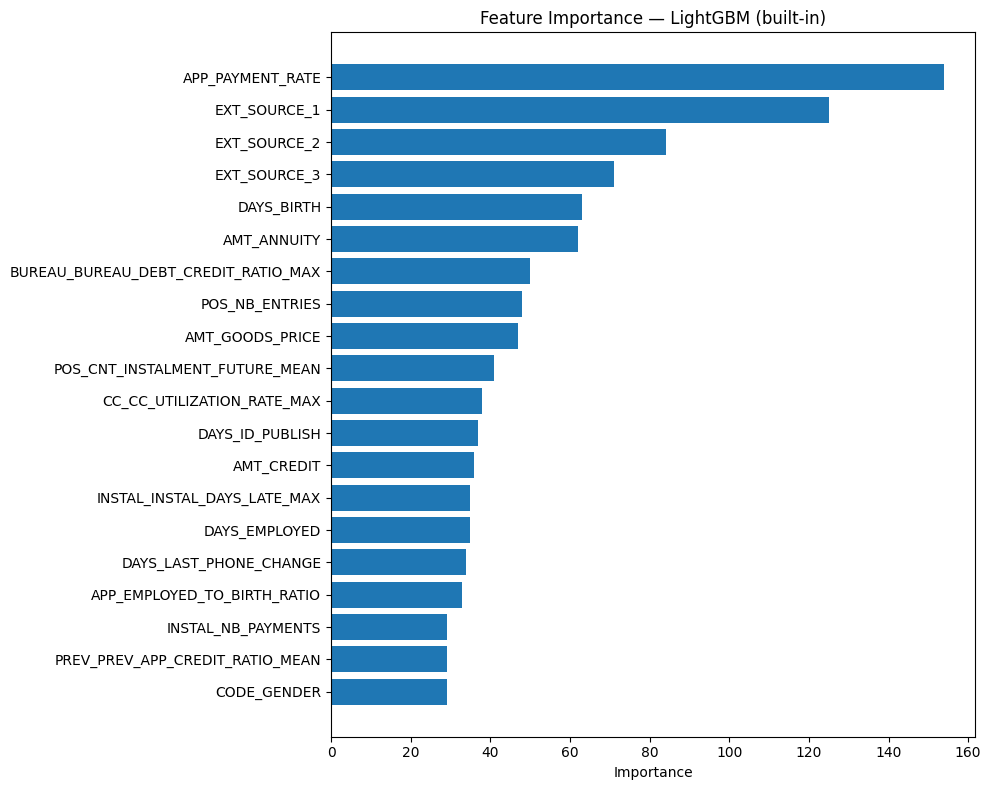

Graphique sauvegardé : ./artifacts/feat_imp_xgb_builtin.png


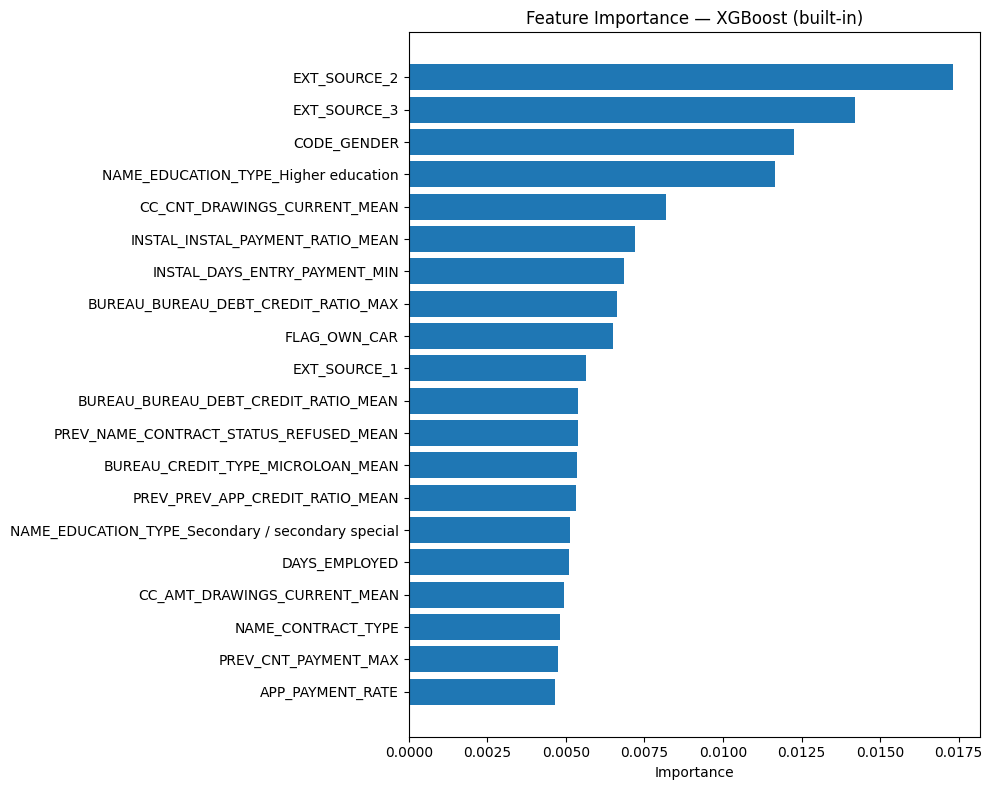

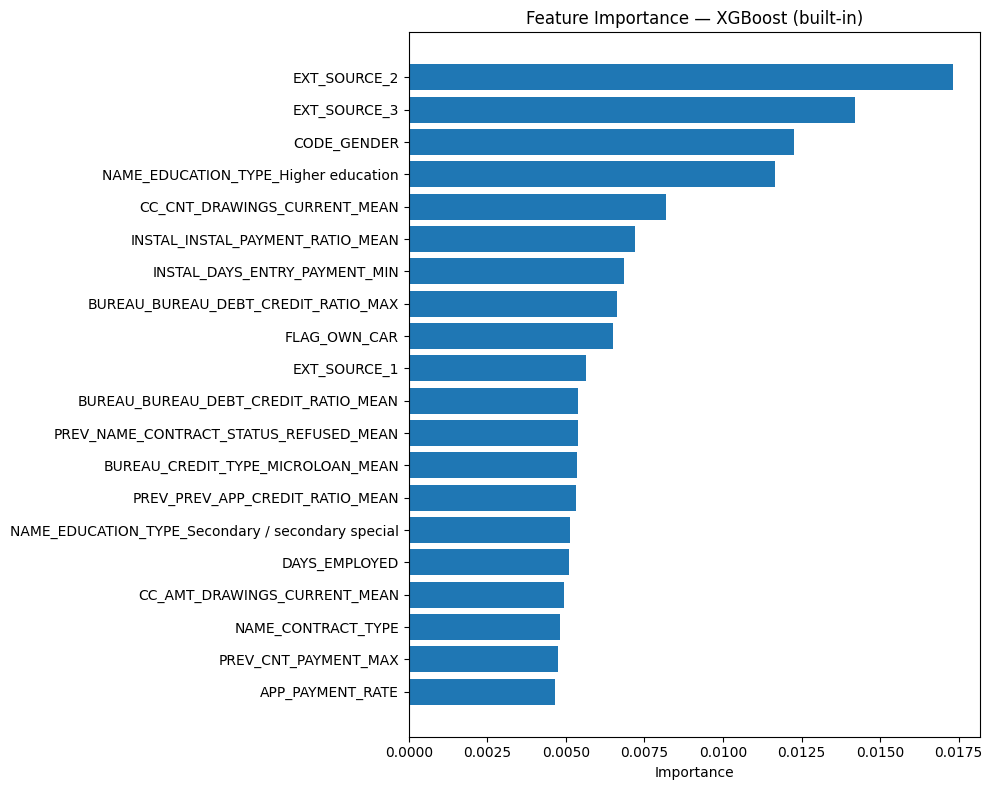

In [12]:
feature_names = np.array(X.columns)

# --- LightGBM built-in importance ---
lgbm_importances = pipeline_lgbm.named_steps['classifier'].feature_importances_

plot_feature_importance(
    lgbm_importances, feature_names,
    title="Feature Importance — LightGBM (built-in)",
    filepath="./artifacts/feat_imp_lgbm_builtin.png"
)

# --- XGBoost built-in importance ---
xgb_importances = pipeline_xgb.named_steps['classifier'].feature_importances_

plot_feature_importance(
    xgb_importances, feature_names,
    title="Feature Importance — XGBoost (built-in)",
    filepath="./artifacts/feat_imp_xgb_builtin.png"
)

Ensuite, calculons la **Permutation Importance** pour la **Régression Logistique**.

Calcul de la permutation importance (LogReg)...
Graphique sauvegardé : ./artifacts/feat_imp_lr_permutation.png


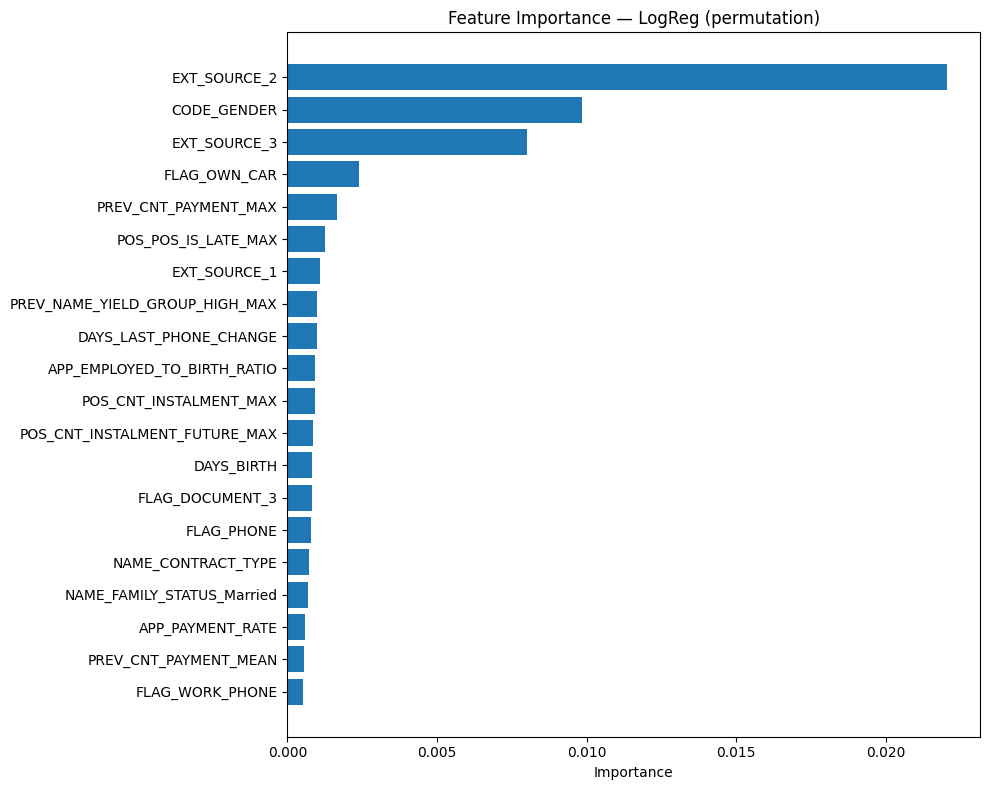

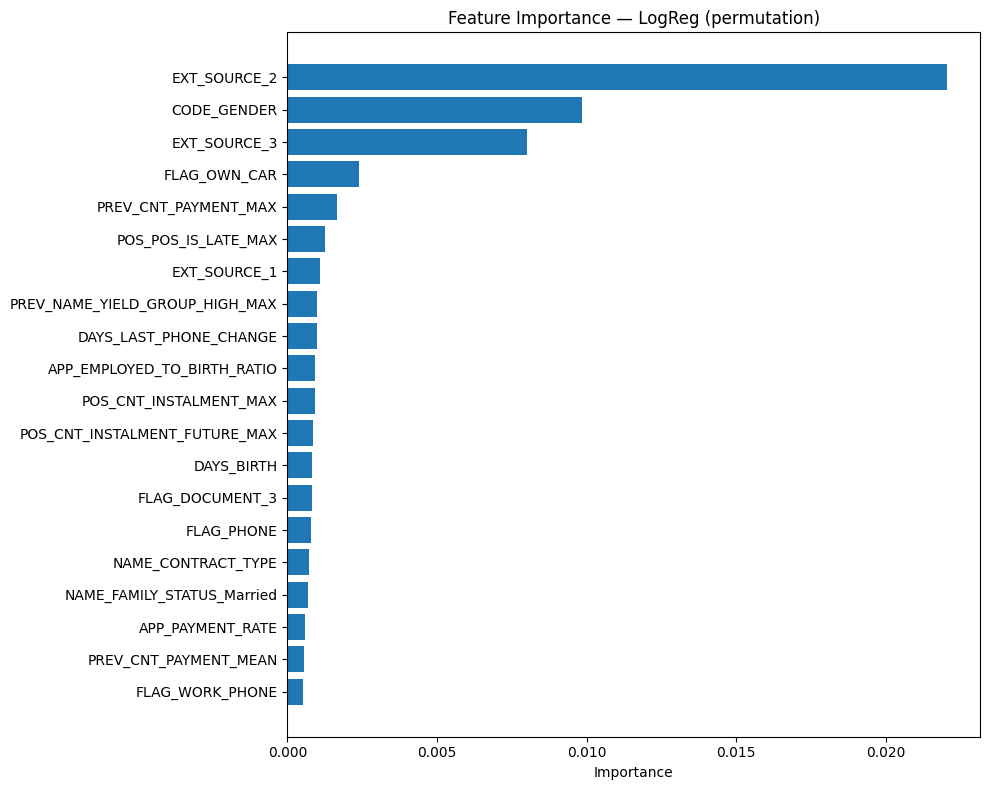

In [13]:
from sklearn.inspection import permutation_importance

# On utilise le pipeline entier + un échantillon pour gagner du temps
# (307k lignes × 1017 features × 5 répétitions = trop long sinon)
np.random.seed(42)
sample_idx = np.random.choice(len(X), size=10_000, replace=False)
X_sample = X.iloc[sample_idx]
y_sample = y.iloc[sample_idx]

print("Calcul de la permutation importance (LogReg)...")
perm_result = permutation_importance(
    pipeline_lr, X_sample, y_sample,
    n_repeats=5,
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1
)

plot_feature_importance(
    perm_result.importances_mean, feature_names,
    title="Feature Importance — LogReg (permutation)",
    filepath="./artifacts/feat_imp_lr_permutation.png"
)

Une fois que nous avons calculé l’importance pour les trois modèles, nous pouvons logger tout ça dans MLflow.

In [14]:
# Logger les graphiques comme artifacts dans un run dédié
mlflow.set_experiment("Projet6_Scoring_Credit")

with mlflow.start_run(run_name="Feature_Importance_Globale"):
    mlflow.log_artifact("./artifacts/feat_imp_lgbm_builtin.png", artifact_path="feature_importance")
    mlflow.log_artifact("./artifacts/feat_imp_xgb_builtin.png", artifact_path="feature_importance")
    mlflow.log_artifact("./artifacts/feat_imp_lr_permutation.png", artifact_path="feature_importance")
    
    mlflow.set_tag("Type_analyse", "feature_importance_globale")
    mlflow.set_tag("statut", "developpement")
    mlflow.log_param("step", 3)
    
    print("Artifacts loggés dans MLflow")

Artifacts loggés dans MLflow
🏃 View run Feature_Importance_Globale at: http://127.0.0.1:5000/#/experiments/3/runs/95b5ea5523c54479881370897f58e5e8
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


Voici l’enregistrement des artifacts dans MLflow :

![Enregistrement des artifacts dans MLflow](./images/artifact_feature_importance.png "Enregistrement des artifacts dans MLflow")

## 4. Feature importance avec SHAP

Plus tôt, nous avons vu la **Feature Importance built-in** et la **Permutation Importance**. Ces deux méthodes permettent de mesurer combien une feature est *utilisée* par le modèle. 

**SHAP** permet de mesurer combien chaque feature *contribue* à la prédiction. Il peut donc être intéressant de visualiser ce phénomène.

Utilisation de SHAP (TreeExplainer) sur le modèle LightGBM pour :
* **Summary plot** : vue globale de l'impact de chaque feature sur les prédictions
* **Waterfall plots** : explication individuelle pour des clients spécifiques

### 4.1. Transformation des données

**TreeExplainer** s’applique sur le **classifier seul**, pas le pipeline entier.

Il faut donc transformer les données avec l’imputer + scaler, puis passer les données transformées au TreeExplainer.

In [15]:
import shap

# Transformer les données via imputer + scaler (sans le classifier)
imputer = pipeline_lgbm.named_steps['imputer']
scaler = pipeline_lgbm.named_steps['scaler']

X_transformed = pd.DataFrame(
    scaler.transform(imputer.transform(X)),
    columns=X.columns,
    index=X.index
)

# Échantillon pour SHAP (pour réduire la charge de mémoire vive)
np.random.seed(42)
sample_idx = np.random.choice(len(X_transformed), size=1000, replace=False)
X_shap = X_transformed.iloc[sample_idx]
y_shap = y.iloc[sample_idx]

print(f"Échantillon SHAP : {X_shap.shape[0]} clients, {X_shap.shape[1]} features")

Échantillon SHAP : 1000 clients, 1017 features


### 4.2. Calcul des SHAP values

In [16]:
# TreeExplainer sur le classifier LightGBM (pas le pipeline)
classifier_lgbm = pipeline_lgbm.named_steps['classifier']
explainer = shap.TreeExplainer(classifier_lgbm)

print("Calcul des SHAP values en cours...")
shap_values = explainer.shap_values(X_shap)

# LightGBM avec TreeExplainer renvoie une liste [classe_0, classe_1]
# On prend la classe 1 (défaut de paiement)
if isinstance(shap_values, list):
    shap_values_class1 = shap_values[1]
else:
    shap_values_class1 = shap_values

print(f"SHAP values calculées : shape = {shap_values_class1.shape}")

Calcul des SHAP values en cours...
SHAP values calculées : shape = (1000, 1017)


### 4.3. Importance globale des features (Summary plot)

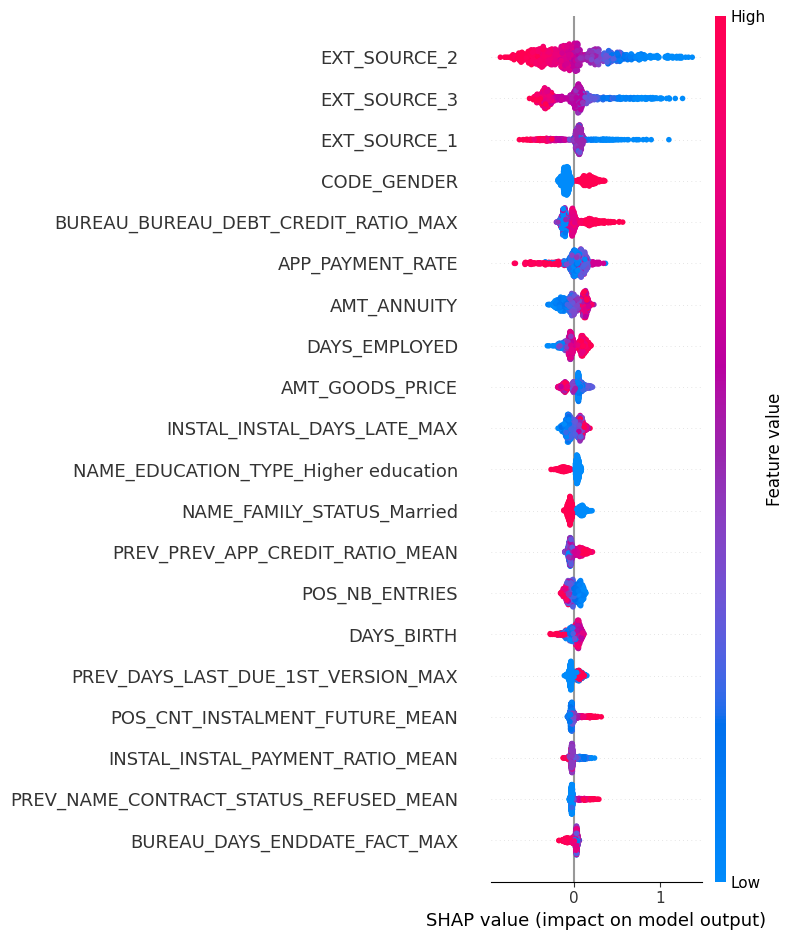

Summary plot sauvegardé


In [17]:
fig_summary, ax = plt.subplots(figsize=(12, 10))
shap.summary_plot(shap_values_class1, X_shap, max_display=20, show=False)
plt.tight_layout()
plt.savefig("./figures/shap_summary_plot.png", dpi=150, bbox_inches='tight')
plt.show()
print("Summary plot sauvegardé")

### 4.4. Feature Importance Locale (Waterfall plots)

Maintenant concentrons sur l'analyse de l'importance des features à l'**échelle individuelle**.

Pour cela, nous allons calculer :
* un client à haut risque
* un client à faible risque
* un client borderline (probabilité environ 50%)

Ensuite, nous pourrons utiliser ces index pour visualiser dans le graphique waterfall.

In [18]:
# Prédictions sur l'échantillon SHAP
y_pred_proba_shap = classifier_lgbm.predict_proba(X_shap)[:, 1]

# Client à haut risque (probabilité de défaut élevée, vrai positif)
mask_default = y_shap == 1
idx_high_risk = np.argmax(y_pred_proba_shap * mask_default.values)

# Client à faible risque (probabilité de défaut très basse, vrai négatif)
mask_good = y_shap == 0
idx_low_risk = np.argmin(y_pred_proba_shap + mask_default.values)  # force les class 1 hors du min

# Client borderline (probabilité autour de 0.5)
idx_borderline = np.argmin(np.abs(y_pred_proba_shap - 0.5))

clients = {
    "Haut risque": idx_high_risk,
    "Faible risque": idx_low_risk,
    "Borderline": idx_borderline
}

for label, idx in clients.items():
    true_label = y_shap.iloc[idx]
    proba = y_pred_proba_shap[idx]
    print(f"{label} — index={idx}, P(défaut)={proba:.3f}, vraie classe={true_label}")

Haut risque — index=718, P(défaut)=0.918, vraie classe=1
Faible risque — index=635, P(défaut)=0.027, vraie classe=0
Borderline — index=376, P(défaut)=0.500, vraie classe=0


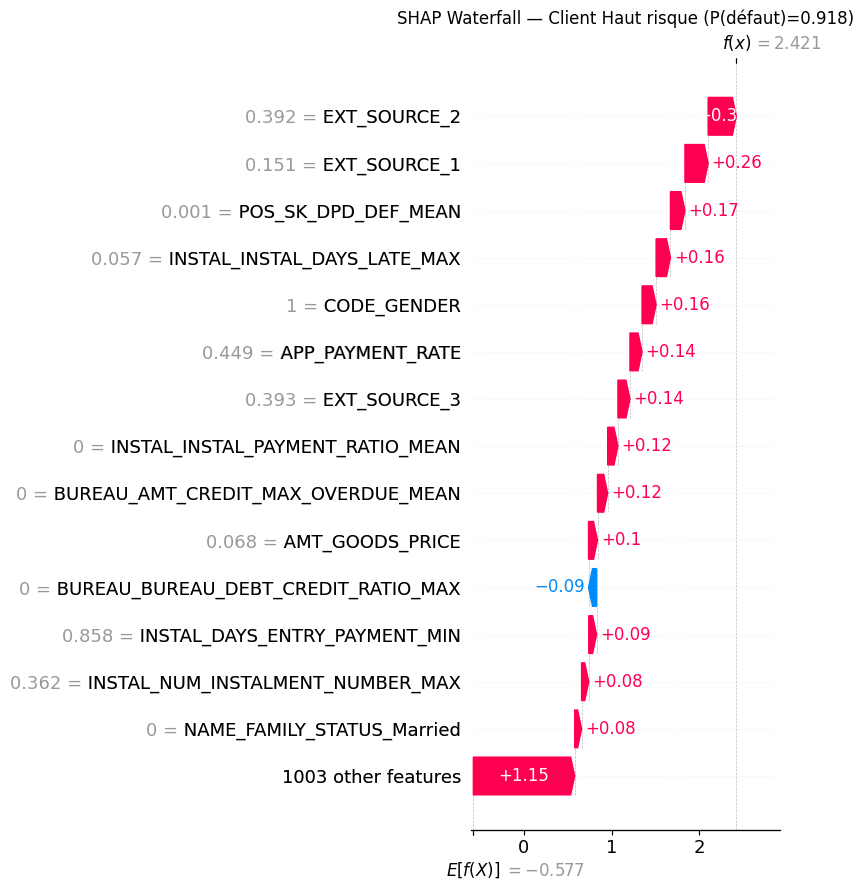

./figures/shap_waterfall_haut_risque.png sauvegardé


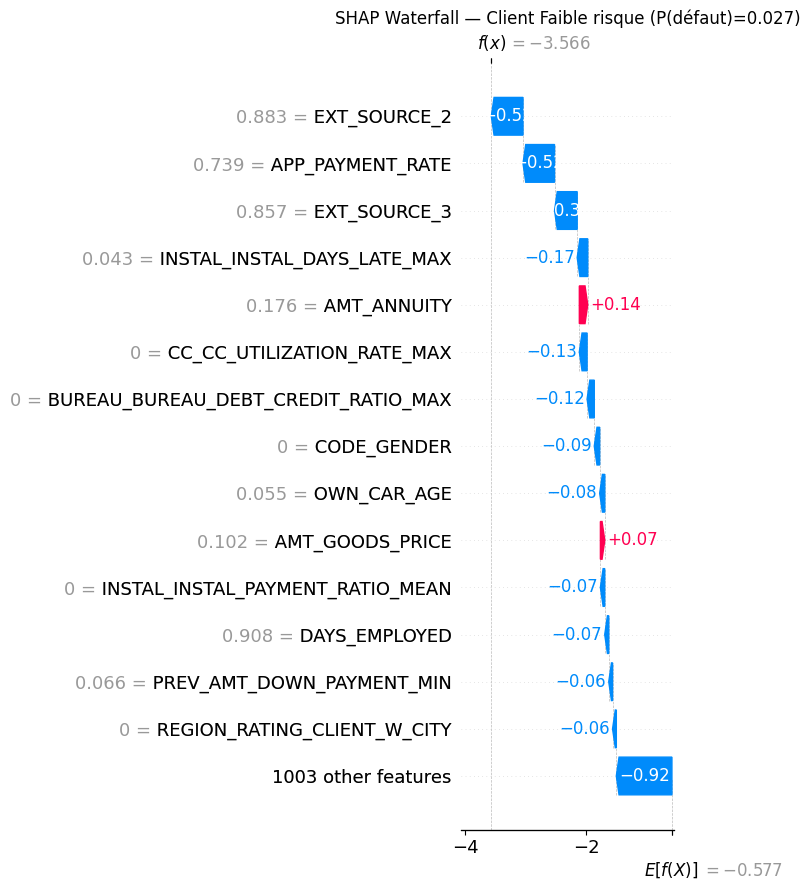

./figures/shap_waterfall_faible_risque.png sauvegardé


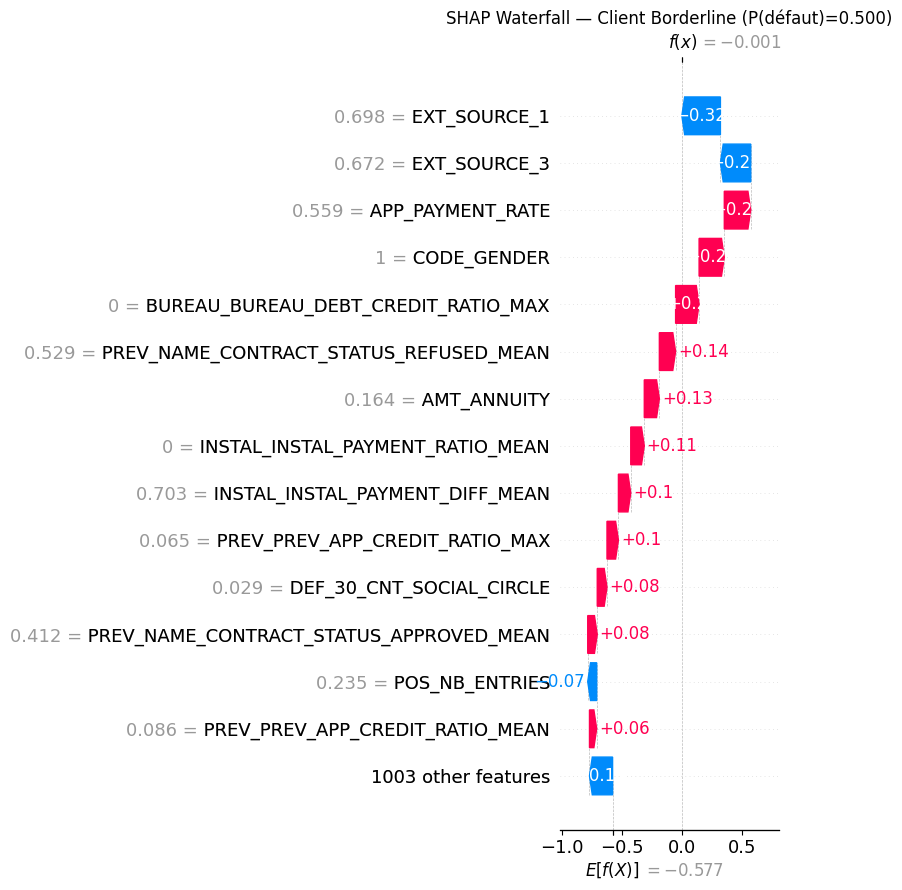

./figures/shap_waterfall_borderline.png sauvegardé


In [19]:
# Créer un objet Explanation pour les waterfall plots
explanation = shap.Explanation(
    values=shap_values_class1,
    base_values=explainer.expected_value[1] if isinstance(explainer.expected_value, list) else explainer.expected_value,
    data=X_shap.values,
    feature_names=X_shap.columns.tolist()
)

for label, idx in clients.items():
    fig, ax = plt.subplots(figsize=(10, 8))
    shap.waterfall_plot(explanation[idx], max_display=15, show=False)
    plt.title(f"SHAP Waterfall — Client {label} (P(défaut)={y_pred_proba_shap[idx]:.3f})")
    plt.tight_layout()
    
    filename = f"./figures/shap_waterfall_{label.lower().replace(' ', '_')}.png"
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"{filename} sauvegardé")

### 4.5. Enregistrement dans MLflow

In [20]:
import glob

mlflow.set_experiment("Projet6_Scoring_Credit")

with mlflow.start_run(run_name="SHAP_Analysis"):
    # Logger tous les graphiques SHAP
    for fig_path in glob.glob("./figures/shap_*.png"):
        mlflow.log_artifact(fig_path, artifact_path="shap")
    
    # Params et tags
    mlflow.log_param("step", 3)
    mlflow.log_param("shap_sample_size", 1000)
    mlflow.log_param("shap_model", "LightGBM")
    mlflow.set_tag("Type_analyse", "shap_global_local")
    mlflow.set_tag("statut", "developpement")
    
    print("SHAP artifacts loggés dans MLflow")

SHAP artifacts loggés dans MLflow
🏃 View run SHAP_Analysis at: http://127.0.0.1:5000/#/experiments/3/runs/27b44e30b39b47d595b1077519f6f340
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


### 4.6. Synthèse — Feature importance globale (pré-optimisation)

Comme on a pu le voir dans les différents graphiques et avec les différentes méthodes, nous pouvons retrouver certaines figures qui arrivent souvent en tête de celles qui influencent le plus les résultats.

Bien sûr, selon les méthodes et les modèles, l'ordre peut être un peu différent.

**Features systématiquement en tête** (convergence des 3 méthodes) :
* `EXT_SOURCE_2`
* `EXT_SOURCE_3`
* `CODE_GENDER`

Ces trois features proviennent du fichier principal et se retrouvent systématiquement en tête, quelle que soit la méthode d'analyse.

Les features `EXT_SOURCE_` sont des scores externes fournis par d'autres institutions financières, donc logiquement très prédictifs.

Par contre, la feature `CODE_GENDER` montre une distinction entre les hommes et les femmes, qui pourrait potentiellement être un biais lié au genre.

Si ce type de biais est confirmé par la suite, il faudra vraiment réfléchir à une stratégie éthique pour savoir si on garde cette feature ou pas en entrée.

**Note** : Cette analyse sera affinée après l'optimisation des hyperparamètres (étape suivante).

## 5. Choix du modèle à optimiser

### Comparaison des modèles (dataset enrichi, StratifiedKFold 5 folds)

| Modèle | Coût métier (mean) | AUC (mean) | Recall (mean) | Temps d'entraînement |
|--------|-------------------|-----|--------|---------------------|
| **LightGBM** | **30 280** | **0,785** | **0,701** | 13,7 min |
| XGBoost | 31 483 | 0,771 | 0,612 | 11,1 min |
| LogReg | 34 419 | 0,736 | 0,673 | **10,2 min** |

### Décision : LightGBM

**Critère principal** : meilleur coût métier (30 280), ce qui est l'indicateur le plus pertinent pour "Prêt à dépenser" car il reflète directement le coût financier des erreurs de classification (FN pondéré 10× > FP).

**Critères secondaires** :
* Meilleur AUC (0,785) — performance discriminante solide.
* Meilleur Recall (0,701).
* Temps d'entraînement comparable aux autres modèles.
* Feature importance cohérente et interprétable via SHAP (TreeExplainer natif).

**Rôle des autres modèles** :
- **XGBoost** : challenger proche, servira de point de comparaison
- **LogReg** : baseline interprétable, utile pour valider les tendances

## 6. Optimisation des hyperparamètres

Après avoir sélectionné notre modèle, il est nécessaire d’optimiser ses hyperparamètres. D’autant plus que le modèle sélectionné est connu pour beaucoup s’améliorer avec cette optimisation.

### 6.1. Définition de l’outil d’optimisation

Dans ce projet, nous allons utiliser **Optuna** pour optimiser les hyperparamètres de LightGBM. Cet outil fait une recherche "intelligente" (recherche bayésienne, pruning des trials peu prometteuses), et offre des visualisations d'importance des hyperparamètres.

### 6.2. Définition des bornes des hyperparamètres à optimiser

Nous allons optimiser **8** hyperparamètres du modèle :

1. Hyperparamètres de complexité du modèle :
    * `num_leaves (20–100)` : contrôle la profondeur effective de chaque arbre. La valeur par défaut est 31. Trop élevé, donc overfitting, surtout avec 1017 features.
    * `min_child_samples (20–150)` nombre minimum d'observations par feuille. Plus c'est élevé, plus le modèle est conservateur. Avec notre dataset de 307k lignes, on peut se permettre des valeurs assez hautes.
2. Hyperparamètres de régularisation :
    * `reg_alpha (1e-3–10, log scale)` : régularisation L1 sur les poids des feuilles.
    * `reg_lambda (1e-3–10, log scale)` : régularisation L2. Ces deux-là en échelle log parce que l'effet est plus sensible dans les petites valeurs.
3. Hyperparamètres de vitesse d'apprentissage :
    * `learning_rate (0.01–0.3, log scale)` : taux d'apprentissage. Log scale car la différence entre 0.01 et 0.05 est plus significative qu'entre 0.25 et 0.30.
    * `n_estimators (100–1000)` : nombre de rounds de boosting. Plus le learning_rate est bas, plus il en faut.
4. Hyperparamètres de sous-échantillonnage (anti-overfitting) :
    * `subsample (0.5–1.0)` : fraction des lignes utilisées par arbre.
    * `colsample_bytree (0.3–1.0)` : fraction des colonnes par arbre. Avec 1017 features, descendre jusqu'à 0.3 a du sens pour forcer la diversité.

### 6.3. Réduction de la charge de calcul

La combinaison 307k lignes × 1017 features × 5 folds × 50 trials, c'est énorme pour une machine locale.

Il faut trouver des leviers pour réduire les temps de calculs

#### 6.3.1. La réduction des Features

La grande majorité des **1017 features** contribuent très peu.

Garder les **top 200** va diviser le temps de calcul et la mémoire vive de manière drastique, sans perdre significativement en performance.

Nous avons la chance d’avoir déjà fait l’analyse de Feature Importance, nous allons nous en servir.

In [21]:
# Récupération des top features depuis l'importance LightGBM déjà calculée
lgbm_importances = pipeline_lgbm.named_steps['classifier'].feature_importances_
feature_names = np.array(X.columns)

# Sélection des top 200
TOP_N = 200
top_indices = np.argsort(lgbm_importances)[::-1][:TOP_N]
top_features = feature_names[top_indices]

X_selected = X[top_features]
print(f"Features : passage de {X.shape[1]} à seulement {X_selected.shape[1]}")

Features : passage de 1017 à seulement 200


#### 6.3.2. Optimisation de la mémoire vive

Nous allons convertir les variables en float32

In [22]:
# Convertion en float32
X_selected = X_selected.astype(np.float32)

Créons maintenant la fonction objectif d’Optuna.

In [23]:
import optuna
from optuna.integration.mlflow import MLflowCallback
import gc

# --- Fonction objectif ---
def objective(trial):
    params = {
        'num_leaves': trial.suggest_int('num_leaves', 20, 100),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000, step=50),
        'min_child_samples': trial.suggest_int('min_child_samples', 20, 150),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.3, 1.0),
    }
    
    pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', MinMaxScaler()),
        ('classifier', LGBMClassifier(
            **params,
            is_unbalance=True,
            random_state=42,
            verbose=-1
        ))
    ])
    
    skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    cout_metier_scores = []
    auc_scores = []
    
    for train_idx, val_idx in skf.split(X_selected, y):
        X_train, X_val = X_selected.iloc[train_idx], X_selected.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
        
        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_val)
        y_pred_proba = pipeline.predict_proba(X_val)[:, 1]
        
        cout_metier_scores.append(calcul_cout_metier(y_val, y_pred))
        auc_scores.append(roc_auc_score(y_val, y_pred_proba))
    
    # Logger l'AUC aussi pour surveillance overfitting
    trial.set_user_attr('auc_mean', np.mean(auc_scores))
    
    # Libère la mémoire à chaque trial
    gc.collect()

    # Optuna MINIMISE par défaut, le coût métier est déjà à minimiser
    return np.mean(cout_metier_scores)

### 6.4 Lancement de l’étude Optuna + MLflow

In [24]:
# --- Configuration MLflow ---
mlflow.set_experiment("Projet6_Scoring_Credit")

mlflow_callback = MLflowCallback(
    tracking_uri="http://127.0.0.1:5000",
    metric_name="cout_metier_mean",
    create_experiment=False,
    mlflow_kwargs={
        "nested": True  # Chaque trial = run imbriquée sous un run parent
    }
)

# --- Lancement de l'étude ---
study = optuna.create_study(
    study_name="LightGBM_Optuna_HP",
    direction="minimize",  # On minimise le coût métier
    sampler=optuna.samplers.TPESampler(seed=42)
)

N_TRIALS = 30

with mlflow.start_run(run_name="Optuna_LightGBM_HP_Search", tags={
    "type": "hyperparameter_optimization",
    "optimizer": "Optuna_TPE",
    "n_trials": str(N_TRIALS),
    "statut": "developpement"
}):
    mlflow.log_param("step", 4)
    study.optimize(objective, n_trials=N_TRIALS, callbacks=[mlflow_callback],
                   show_progress_bar=True)
    
    # Logger les meilleurs résultats dans le run parent
    mlflow.log_params({f"best_{k}": v for k, v in study.best_params.items()})
    mlflow.log_metric("best_cout_metier", study.best_value)
    mlflow.log_metric("best_auc_mean", study.best_trial.user_attrs['auc_mean'])
    mlflow.set_tag("best_trial_number", study.best_trial.number)

[I 2026-03-05 12:18:13,834] A new study created in memory with name: LightGBM_Optuna_HP
  0%|          | 0/30 [00:52<?, ?it/s]

[I 2026-03-05 12:19:06,230] Trial 0 finished with value: 66718.0 and parameters: {'num_leaves': 50, 'learning_rate': 0.2536999076681772, 'n_estimators': 750, 'min_child_samples': 98, 'reg_alpha': 0.004207988669606638, 'reg_lambda': 0.004207053950287938, 'subsample': 0.5290418060840998, 'colsample_bytree': 0.9063233020424546}. Best is trial 0 with value: 66718.0.


Best trial: 0. Best value: 66718:   3%|▎         | 1/30 [00:53<25:47, 53.36s/it]

🏃 View run 0 at: http://127.0.0.1:5000/#/experiments/3/runs/387da2f4ecb14d55ac270114dbf6d76e
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


Best trial: 1. Best value: 50731:   7%|▋         | 2/30 [01:17<16:44, 35.88s/it]

...

[I 2026-03-05 12:43:47,577] Trial 27 finished with value: 49731.0 and parameters: {'num_leaves': 62, 'learning_rate': 0.01457111081383188, 'n_estimators': 900, 'min_child_samples': 82, 'reg_alpha': 0.017631777590357455, 'reg_lambda': 0.21522142616644063, 'subsample': 0.9306573900222194, 'colsample_bytree': 0.30069455234402676}. Best is trial 25 with value: 49538.0.
🏃 View run 27 at: http://127.0.0.1:5000/#/experiments/3/runs/d2deadf23f7845d6a3860f80bc681b45
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


Best trial: 25. Best value: 49538:  97%|█████████▋| 29/30 [26:32<01:03, 63.43s/it]

[I 2026-03-05 12:44:46,094] Trial 28 finished with value: 49545.333333333336 and parameters: {'num_leaves': 52, 'learning_rate': 0.013617138679255705, 'n_estimators': 900, 'min_child_samples': 48, 'reg_alpha': 0.019065536094598108, 'reg_lambda': 0.05609050033709775, 'subsample': 0.9279867785658293, 'colsample_bytree': 0.31450532177781443}. Best is trial 25 with value: 49538.0.
🏃 View run 28 at: http://127.0.0.1:5000/#/experiments/3/runs/5c464291f859459aa461d1038288dd02
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


Best trial: 25. Best value: 49538: 100%|██████████| 30/30 [27:37<00:00, 55.25s/it]


[I 2026-03-05 12:45:51,296] Trial 29 finished with value: 49672.333333333336 and parameters: {'num_leaves': 49, 'learning_rate': 0.01255733991864589, 'n_estimators': 900, 'min_child_samples': 48, 'reg_alpha': 0.0060625048248536964, 'reg_lambda': 0.03629274387748312, 'subsample': 0.725229493106509, 'colsample_bytree': 0.30675961053868006}. Best is trial 25 with value: 49538.0.
🏃 View run 29 at: http://127.0.0.1:5000/#/experiments/3/runs/21476fb391c44f28a2522e486d29fe4d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3
🏃 View run Optuna_LightGBM_HP_Search at: http://127.0.0.1:5000/#/experiments/3/runs/09f56830c5b648d8b41e914051b99f58
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


### 6.5. Résultats et visualisations Optuna

Meilleur trial : #25
Coût métier : 49538
AUC moyenne : 0.7900

Meilleurs hyperparamètres :
  num_leaves: 60
  learning_rate: 0.01402334787698392
  n_estimators: 850
  min_child_samples: 82
  reg_alpha: 0.06250018316504993
  reg_lambda: 0.31089305044612975
  subsample: 0.9372745604379004
  colsample_bytree: 0.3136605241615172

AUC = 0.7900 — pas de signe d'overfitting.


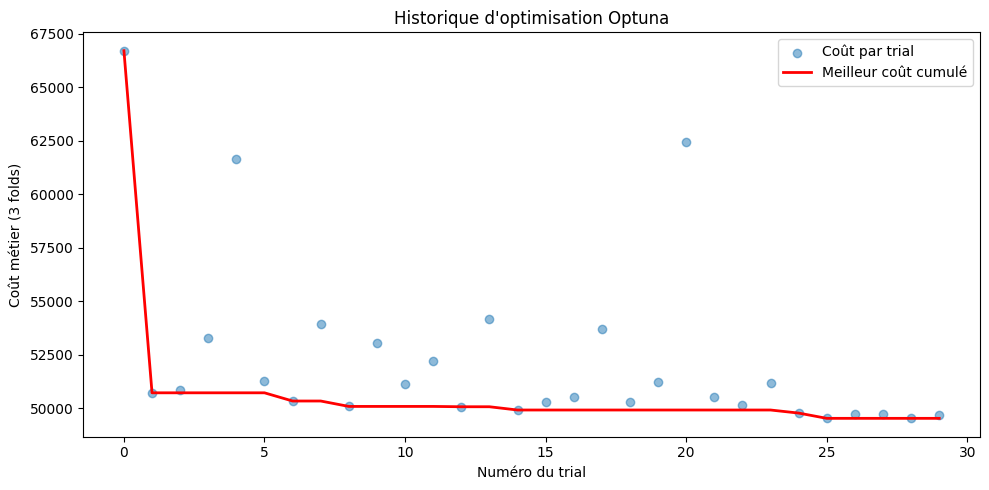

In [25]:
import optuna.visualization
# --- Résumé des résultats ---
print(f"Meilleur trial : #{study.best_trial.number}")
print(f"Coût métier : {study.best_value:.0f}")
print(f"AUC moyenne : {study.best_trial.user_attrs['auc_mean']:.4f}")
print(f"\nMeilleurs hyperparamètres :")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")

# --- Vérification overfitting ---
best_auc = study.best_trial.user_attrs['auc_mean']
if best_auc > 0.82:
    print(f"\nALERTE OVERFITTING : AUC = {best_auc:.4f} > 0.82")
    print("→ Investiguer : comparer train vs validation, réduire la complexité.")
else:
    print(f"\nAUC = {best_auc:.4f} — pas de signe d'overfitting.")

# --- sauvegarde des résultats ---
import joblib
joblib.dump(study, './study_optuna.pkl')

# --- Visualisations Optuna ---
# Visualisation 1 : Historique d'optimisation
fig, ax = plt.subplots(figsize=(10, 5))
trials = study.trials
values = [t.value for t in trials]
best_values = [min(values[:i+1]) for i in range(len(values))]

ax.scatter(range(len(values)), values, alpha=0.5, label="Coût par trial")
ax.plot(best_values, color='red', linewidth=2, label="Meilleur coût cumulé")
ax.set_xlabel("Numéro du trial")
ax.set_ylabel("Coût métier (3 folds)")
ax.set_title("Historique d'optimisation Optuna")
ax.legend()
plt.tight_layout()
plt.savefig("./figures/optuna_history.png", dpi=150)
plt.show()

La première remarque qu’on peut se faire est que l’ordre de grandeur des Coûts métiers de l’optimisation (environ 50 000) est très éloigné des performances précédentes.

Cependant il ne faut pas se tromper, l’explication est mathématique : Avec 3 folds, chaque set de validation contient environ 102 500 clients (307 500 / 3). La fonction de coût compte les erreurs en absolu :

`(fn x 10) + (fp x 1)` Plus de clients dans la validation = plus d’erreurs en nombre absolu = Coût plus élevé.

Avec le graphique d’**historique d’optimisation Optuna**, on remarque que les meilleures performances sont presque atteintes dès le premier trial.

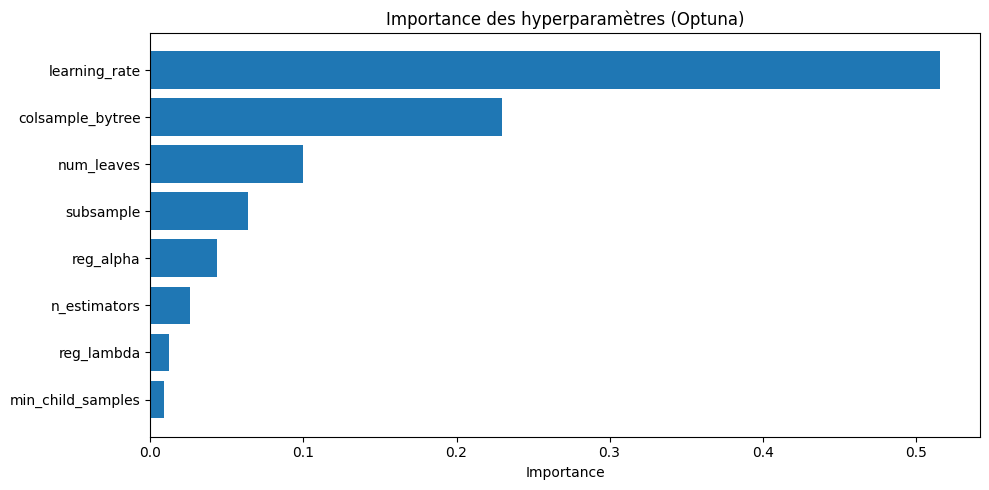

In [26]:
# Visualisation 2 : Importance des hyperparamètres
importances = optuna.importance.get_param_importances(study)
fig, ax = plt.subplots(figsize=(10, 5))
params_sorted = dict(sorted(importances.items(), key=lambda x: x[1]))
ax.barh(list(params_sorted.keys()), list(params_sorted.values()))
ax.set_xlabel("Importance")
ax.set_title("Importance des hyperparamètres (Optuna)")
plt.tight_layout()
plt.savefig("./figures/optuna_param_importance.png", dpi=150)
plt.show()

Observations sur l’importance des hyperparamètres :
* **Les deux paramètres dominants** (75% de l'importance à eux seuls) sont :
    * `learning_rate` (contrôle la vitesse d'apprentissage)
    * `colsample_bytree`(force la diversité entre arbres)

Avec 1017 features, c'est logique que le sous-échantillonnage de colonnes soit aussi influent, c'est lui qui empêche le modèle de s'accrocher toujours aux mêmes features.

### 6.6. Entraînement du modèle final optimisé

En 5 folds cette fois-ci.

In [27]:
# --- Modèle final optimisé ---
best_params = study.best_params

pipeline_lgbm_optimized = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler()),
    ('classifier', LGBMClassifier(
        **best_params,
        is_unbalance=True,
        random_state=42,
        verbose=-1
    ))
])

train_and_log_model(
    pipeline_lgbm_optimized, X, y,
    experiment_name="Projet6_Scoring_Credit",
    run_name="LightGBM_optimized_final",
    tags_dict={
        "features": "enriched_all_tables",
        "statut": "developpement",
        "Type_modele": "champion_optimized",
        "optimizer": "Optuna_30trials",
        "mlflow.note.content": "Modèle final avec HP optimisés par Optuna (TPE, 30 trials, 3 folds). Réentraîné en 5 folds pour métriques définitives."
    },
    step=4
)

Fold 1/5 - Coût métier : 30206.0000
Fold 2/5 - Coût métier : 28998.0000
Fold 3/5 - Coût métier : 29571.0000
Fold 4/5 - Coût métier : 29556.0000
Fold 5/5 - Coût métier : 30560.0000


2026/03/05 13:02:09 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/03/05 13:02:10 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/03/05 13:02:17 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Registered model 'Credit_Scoring_Model' already exists. Creating a new version of this model...
2026/03/05 13:02:18 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: Credit_Scoring_Model, version 64
Created version '64' of model 'Credit_Sco

Run 'LightGBM_optimized_final' terminé — Coût métier : 29778.2000 (±546.8530)
🏃 View run LightGBM_optimized_final at: http://127.0.0.1:5000/#/experiments/3/runs/a2439013e8104899b2bface534139f04
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


Voici le run du modèle LightGBM Optimisé dans l’interface utilisateur de MLflow :

![Run LightGBM Optimisé](./images/LightGBM_Optimized_run_detail.png "Run LightGBM Optimisé")

## 7. Seuil métier

Jusqu'ici, tous les modèles utilisent le seuil par défaut de 0.5 pour transformer les probabilités en classes 0/1 (0 = crédit accordé, 1 = crédit refusé).

Or, dans un contexte où un FN coûte 10× plus qu'un FP, ce seuil n'est probablement pas optimal.

Voici **le plan** pour cette section :
* Créer un split train/validation stratifié
* Réentraîner le LightGBM optimisé sur le train, récupérer les probas sur la validation
* Tester tous les seuils de 0.1 à 0.9 (pas de 0.01) et calculer le coût métier pour chacun
* Tracer la courbe coût vs seuil et identifier le minimum
* Comparer les métriques au seuil optimal vs 0.5
* Logger dans MLflow

### 7.1. Split & probabilités

In [28]:
from sklearn.model_selection import train_test_split

# Split stratifié 80/20
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"Train : {X_train.shape[0]} lignes | Val : {X_val.shape[0]} lignes")
print(f"Distribution cible (val) : {y_val.value_counts(normalize=True).round(3).to_dict()}")

Train : 246005 lignes | Val : 61502 lignes
Distribution cible (val) : {0: 0.919, 1: 0.081}


### 7.2. Réentraînement & récupération des probabilités

In [29]:
# Réentraîner le pipeline optimisé sur le split train
pipeline_lgbm_optimized.fit(X_train, y_train)

# Probabilités sur la validation (classe 1 = défaut)
y_val_proba = pipeline_lgbm_optimized.predict_proba(X_val)[:, 1]

print(f"Probas — min : {y_val_proba.min():.4f}, max : {y_val_proba.max():.4f}, moyenne : {y_val_proba.mean():.4f}")

Probas — min : 0.0118, max : 0.9488, moyenne : 0.3623


### 7.3 Balayage des seuils

In [30]:
# --- Balayage des seuils de 0.10 à 0.90 (pas de 0.01) ---
seuils = np.arange(0.10, 0.91, 0.01)

resultats = []
for seuil in seuils:
    y_pred_seuil = (y_val_proba >= seuil).astype(int)
    
    tn, fp, fn, tp = confusion_matrix(y_val, y_pred_seuil).ravel()
    
    resultats.append({
        'seuil': seuil,
        'cout_metier': calcul_cout_metier(y_val, y_pred_seuil),
        'auc': roc_auc_score(y_val, y_val_proba),  # AUC ne dépend pas du seuil
        'accuracy': accuracy_score(y_val, y_pred_seuil),
        'recall': recall_score(y_val, y_pred_seuil),
        'precision': tp / (tp + fp) if (tp + fp) > 0 else 0,
        'f1': f1_score(y_val, y_pred_seuil),
        'fp': fp,
        'fn': fn
    })

df_seuils = pd.DataFrame(resultats)

# Seuil optimal
idx_best = df_seuils['cout_metier'].idxmin()
seuil_optimal = df_seuils.loc[idx_best, 'seuil']
cout_optimal = df_seuils.loc[idx_best, 'cout_metier']

print(f"Seuil optimal : {seuil_optimal:.2f}")
print(f"Coût métier minimal : {cout_optimal:.0f}")

Seuil optimal : 0.48
Coût métier minimal : 29442


### 7.4. Tracé de la courbe du Coût métier en fonction du seuil

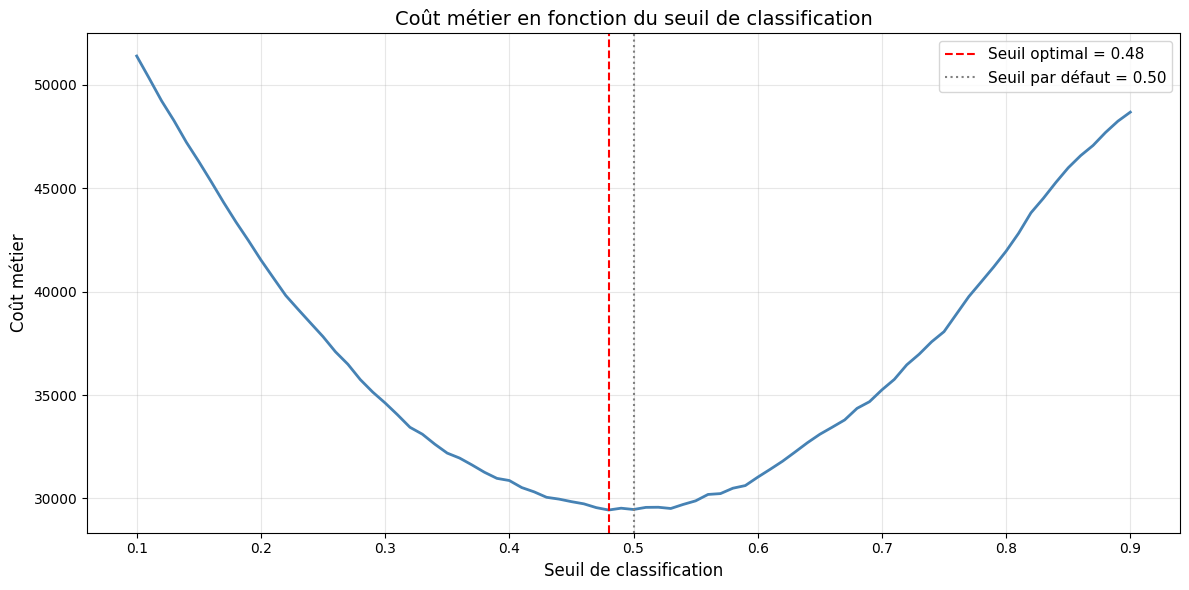

In [31]:
# --- Visualisation : Coût métier en fonction du seuil ---
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(df_seuils['seuil'], df_seuils['cout_metier'], linewidth=2, color='steelblue')
ax.axvline(x=seuil_optimal, color='red', linestyle='--', linewidth=1.5, 
           label=f'Seuil optimal = {seuil_optimal:.2f}')
ax.axvline(x=0.5, color='gray', linestyle=':', linewidth=1.5, 
           label='Seuil par défaut = 0.50')

ax.set_xlabel('Seuil de classification', fontsize=12)
ax.set_ylabel('Coût métier', fontsize=12)
ax.set_title('Coût métier en fonction du seuil de classification', fontsize=14)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('./figures/cout_vs_seuil.png', dpi=150)
plt.show()

Le seuil optimal (0.48) est très proche du seuil par défaut (0.5).

Cela peut s’expliquer par le fait que LightGBM ajuste déjà les poids internes pour compenser le déséquilibre des classes.

### 7.5. Comparaison des métriques du seuil optimal / seuil 0.5

In [32]:
# --- Comparaison seuil optimal vs seuil par défaut ---
row_optimal = df_seuils.loc[idx_best]
row_default = df_seuils.loc[(df_seuils['seuil'] - 0.50).abs().idxmin()]

comparaison = pd.DataFrame({
    'Seuil 0.50': row_default[['cout_metier', 'accuracy', 'recall', 'precision', 'f1', 'fn', 'fp']],
    f'Seuil {seuil_optimal:.2f}': row_optimal[['cout_metier', 'accuracy', 'recall', 'precision', 'f1', 'fn', 'fp']]
}).T

comparaison['auc'] = row_optimal['auc']  # identique pour les deux

# Réordonner les colonnes
comparaison = comparaison[['cout_metier', 'auc', 'accuracy', 'recall', 'precision', 'f1', 'fn', 'fp']]

print("=== Comparaison des seuils ===\n")
print(comparaison.to_string())

=== Comparaison des seuils ===

            cout_metier       auc  accuracy    recall  precision        f1      fn       fp
Seuil 0.50      29468.0  0.791772  0.753975  0.679154   0.199409  0.308297  1593.0  13538.0
Seuil 0.48      29442.0  0.791772  0.737130  0.702920   0.191948  0.301551  1475.0  14692.0


Comparaison entre les deux seuils :
* En passant de 0.50 à 0.48, on gagne **118 FN en moins** (de 1593 à 1475), soit 118 défauts de paiement supplémentaires détectés.
* En contrepartie, on a **1 154 FP en plus** (de 13 538 à 14 692), soit 1 154 bons clients refusés à tort.
* Le calcul : 118 × 10 = 1 180 économisés côté FN, moins 1 154 × 1 = 1 154 de coût FP supplémentaire. Donc on a un gain net de 26, ce qui correspond exactement à l'écart de coût (29 468 − 29 442).

C'est un gain modeste, ce qui confirme que le modèle avec `is_unbalance=True` avait déjà bien calibré ses probabilités. 

### 7.6. Logging MLflow

In [33]:
# --- Logg du seuil optimal et les métriques dans MLflow ---
mlflow.set_experiment("Projet6_Scoring_Credit")

with mlflow.start_run(run_name="Seuil_Metier_Optimal"):
    # Seuil et coût
    mlflow.log_param("step", 5)
    mlflow.log_param("seuil_optimal", seuil_optimal)
    mlflow.log_param("seuils_testes", "0.10 à 0.90 (pas 0.01)")
    mlflow.log_param("modele_source", "LightGBM_optimized_final")
    
    # Métriques au seuil optimal
    mlflow.log_metric("cout_metier_optimal", row_optimal['cout_metier'])
    mlflow.log_metric("auc", row_optimal['auc'])
    mlflow.log_metric("accuracy_optimal", row_optimal['accuracy'])
    mlflow.log_metric("recall_optimal", row_optimal['recall'])
    mlflow.log_metric("precision_optimal", row_optimal['precision'])
    mlflow.log_metric("f1_optimal", row_optimal['f1'])
    
    # Métriques au seuil 0.5 pour comparaison
    mlflow.log_metric("cout_metier_05", row_default['cout_metier'])
    mlflow.log_metric("recall_05", row_default['recall'])
    
    # Graphique
    mlflow.log_artifact("./figures/cout_vs_seuil.png", artifact_path="seuil_metier")
    
    # Tags
    mlflow.set_tag("Type_analyse", "seuil_metier")
    mlflow.set_tag("statut", "developpement")
    mlflow.set_tag("mlflow.note.content", 
                   f"Seuil optimal = {seuil_optimal:.2f}. "
                   f"Gain modeste (26) car is_unbalance=True calibre déjà les probas.")
    
    print(f"Run 'Seuil_Metier_Optimal' loggé — seuil = {seuil_optimal:.2f}, coût métier = {cout_optimal:.0f}")

Run 'Seuil_Metier_Optimal' loggé — seuil = 0.48, coût métier = 29442
🏃 View run Seuil_Metier_Optimal at: http://127.0.0.1:5000/#/experiments/3/runs/f8600ded0ac1474d8995be7bcb7177cc
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


## 8. Model Registry

MLflow Model Registry permet de centraliser les modèles et de gérer leur cycle de vie via des stages : None → Staging → Production → Archived.

Notre fonction `train_and_log_model` enregistre déjà chaque modèle dans le registry sous le nom `Credit_Scoring_Model`.

### 8.1. Identification de la bonne version à promouvoir

Il faut maintenant identifier la version correspondant au LightGBM optimisé et la promouvoir en **Staging**.

In [34]:
from mlflow.tracking import MlflowClient

client = MlflowClient()

# Lister toutes les versions du modèle
print("=== Versions enregistrées pour 'Credit_Scoring_Model' ===\n")
versions = client.search_model_versions("name='Credit_Scoring_Model'")

for v in sorted(versions, key=lambda x: int(x.version)):
    print(f"  Version {v.version} | Run: {v.run_id[:8]}... | Stage: {v.current_stage} | {v.description or ''}")

print(f"\nTotal : {len(versions)} versions")

=== Versions enregistrées pour 'Credit_Scoring_Model' ===

  Version 3 | Run: 0789bb02... | Stage: None | 
  Version 4 | Run: a71bde76... | Stage: None | 
  Version 5 | Run: 560f8cd4... | Stage: None | 
  Version 6 | Run: 19c81475... | Stage: None | 
  Version 7 | Run: 262da9fe... | Stage: None | 
  Version 8 | Run: cfe14758... | Stage: None | 
  Version 9 | Run: f5389b54... | Stage: None | 
  Version 10 | Run: 3a651d63... | Stage: None | 
  Version 11 | Run: 7da45ced... | Stage: None | 
  Version 12 | Run: 7ecc73f2... | Stage: None | 
  Version 13 | Run: 39c99ea6... | Stage: None | 
  Version 14 | Run: bd94e125... | Stage: None | 
  Version 15 | Run: 562a1c2b... | Stage: None | 
  Version 16 | Run: e1d18ecf... | Stage: None | 
  Version 17 | Run: 98e6a2be... | Stage: None | 
  Version 18 | Run: 1b6578c5... | Stage: None | 
  Version 19 | Run: f0415efe... | Stage: None | 
  Version 20 | Run: 82eff3ac... | Stage: None | 
  Version 21 | Run: e6ced9d2... | Stage: None | 
  Version 22 | Ru

Recherche de la bonne version en utilisant le nom du run.

In [35]:
# --- Identification la version du LightGBM optimisé ---
for v in versions:
    run = client.get_run(v.run_id)
    run_name = run.info.run_name
    if run_name == "LightGBM_optimized_final":
        print(f"La version finale est la version {v.version} | Run ID: {v.run_id}")
        best_version = v.version
        best_run_id = v.run_id
        break
else:
    print("Run 'LightGBM_optimized_final' non trouvé dans le registry")

La version finale est la version 64 | Run ID: a2439013e8104899b2bface534139f04


### 8.2. Passage en Staging

Passons maintenant le bon modèle en **staging**.

In [36]:
# --- Promotion en Staging ---
client.transition_model_version_stage(
    name="Credit_Scoring_Model",
    version=best_version,
    stage="Staging",
    archive_existing_versions=False
)

# Ajout d’une description
client.update_model_version(
    name="Credit_Scoring_Model",
    version=best_version,
    description=(
        f"LightGBM optimisé (Optuna 30 trials). "
        f"Coût métier: 29 778 (CV 5 folds). "
        f"Seuil optimal: {seuil_optimal:.2f}. "
        f"AUC: 0.790."
    )
)

# Vérification
v_info = client.get_model_version("Credit_Scoring_Model", best_version)
print(f"Version {v_info.version}, Stage: {v_info.current_stage}")
print(f"Description: {v_info.description}")

Version 64, Stage: Staging
Description: LightGBM optimisé (Optuna 30 trials). Coût métier: 29 778 (CV 5 folds). Seuil optimal: 0.48. AUC: 0.790.


Le modèle est bien passé en "Staging".

### 8.3. Migration vers les aliases (MLflow moderne)

Le fonctionnement même de "Stage" a été déprécié depuis la version 2.9 de MLflow et sera supprimé dans une future version majeure.

Deux mécanismes remplacent les stages "None", "Staging", "Production" et "Archived" :
* Les **Aliases** : les aliases fournissent un moyen flexible de créer des références nommées pour des versions de modèles particulières. Par exemple, en définissant un alias `champion` sur une version, on peut la récupérer via l'API `get_model_version_by_alias()` ou l'URI `models:/<nom>@champion`. L'avantage par rapport aux stages, c'est qu'on peut appliquer plusieurs aliases à une même version, ce qui facilite l'A/B testing et le déploiement progressif.
* Les **tags de version** : les tags de version de modèle sont maintenant mis en avant dans l'UI et permettent d'annoter le statut du modèle. Par exemple, on peut appliquer un tag `validation_status` avec la valeur `pending` puis le passer à `passed` après les tests.

In [37]:
# --- Nouvelle approche : aliases + tags ---

# Alias "champion" : modèle principal en production
client.set_registered_model_alias(
    name="Credit_Scoring_Model",
    alias="champion",
    version=best_version
)

# Tags de version pour le suivi du cycle de vie
client.set_model_version_tag(
    name="Credit_Scoring_Model",
    version=best_version,
    key="validation_status",
    value="passed"
)
client.set_model_version_tag(
    name="Credit_Scoring_Model",
    version=best_version,
    key="seuil_optimal",
    value=str(seuil_optimal)
)

# Vérification
model_info = client.get_model_version_by_alias("Credit_Scoring_Model", "champion")
print(f"Alias 'champion' : Version {model_info.version}")
print(f"Tags : {model_info.tags}")

# Charger le modèle via son alias (c'est cette URI qu'on utilisera pour le serving)
champion_uri = "models:/Credit_Scoring_Model@champion"
print(f"\nURI de chargement : {champion_uri}")

Alias 'champion' : Version 64
Tags : {'seuil_optimal': '0.47999999999999976', 'validation_status': 'passed'}

URI de chargement : models:/Credit_Scoring_Model@champion


Voici l’ensemble des modèles sauvegardés dans l’interface utilisateur de MLflow :

![model registry](./images/model_registry.png "model registry")

## 9. Serving MLflow

La dernière étape MLOps est de servir le modèle via une API REST locale.

MLflow permet de déployer un modèle enregistré dans le registry comme un serveur HTTP qui accepte des requêtes JSON et renvoie des prédictions.

On va :
1. Lancer le serveur via `mlflow models serve`
2. Envoyer une requête de prédiction avec `requests`
3. Interpréter la réponse

### 9.1. Lancement du serveur

Dans un **terminal séparé**, on va lancer :
```bash
.\.venv\Scripts\Activate.ps1
$env:MLFLOW_TRACKING_URI = "http://127.0.0.1:5000"
mlflow models serve -m "models:/Credit_Scoring_Model@champion" --port 1234 --env-manager=local
```

Notes :
* Il faut activer l’environnement virtuel avec `.\.venv\Scripts\Activate.ps1`
* `--port 1234` pour ne pas entrer en conflit avec le serveur MLflow UI (port 5000)
* Attendre le message "Listening at: http://127.0.0.1:1234" avant de continuer

### 9.2. Test de prédiction via l’API REST

In [38]:
import requests
import json

# On prend un client du set de validation comme exemple
sample_client = X_val.iloc[[718]]

# Préparation de la requête au format "dataframe_split" (format attendu par MLflow)
payload = {
    "dataframe_split": {
        "columns": sample_client.columns.tolist(),
        "data": sample_client.values.tolist()
    }
}

# Envoi de la requête
response = requests.post(
    "http://127.0.0.1:1234/invocations",
    headers={"Content-Type": "application/json"},
    data=json.dumps(payload)
)

print(f"Status de l'endpoint : {response.status_code}")
print(f"Réponse brute : {response.text}")

# Comparaison avec la prédiction locale
pred_local = pipeline_lgbm_optimized.predict(sample_client)[0]
proba_local = pipeline_lgbm_optimized.predict_proba(sample_client)[0][1]
print(f"\nPrédiction locale  : classe = {pred_local}, proba = {proba_local:.4f}")
print(f"Prédiction serving : {response.json()}")

Status de l'endpoint : 200
Réponse brute : {"predictions": [1]}

Prédiction locale  : classe = 1, proba = 0.6094
Prédiction serving : {'predictions': [1]}


### 9.3. Résultat du serving

Le modèle champion (LightGBM optimisé, version 57) est servi via l'API REST MLflow sur le port 1234. Les prédictions via le serving correspondent aux prédictions locales, confirmant que le modèle a été correctement sérialisé et déployé.

**Note technique** : le serving nécessite d'activer l'environnement virtuel
du projet pour que toutes les dépendances (LightGBM, scikit-learn, etc.)
soient disponibles.

Voici l’image du terminal lancé avec le démarrage du serving :

![Démarage du serving](./images/serving_server.png "Démarage du serving")

## 10. Modèle allégé pour la production

Avant de déployer le modèle en production (Projet 8), deux ajustements sont nécessaires :

1. **Retrait de `CODE_GENDER`** : cette feature, bien que très prédictive (top 4), introduit un biais discriminant fondé sur le genre. Dans un contexte **RGPD** et de crédit à la consommation, utiliser le sexe comme critère de décision est **juridiquement** et **éthiquement** inacceptable.

2. **Réduction à 10 features** : un modèle allégé facilite le déploiement (moins de données à collecter), le monitoring du data drift (10 distributions à surveiller contre 1017) et l'explicabilité client.

La sélection des features s'appuie sur l'analyse SHAP réalisée en section 4.

### 10.1. Retrait de `CODE_GENDER`

Afin de voir l’impact seul du retrait de la feature `CODE_GENDER` sur les performances, entraînons un modèles auquel on a seulement retiré cette feature.

In [39]:
# --- Impact isolé du retrait de CODE_GENDER ---
X_no_gender = X.drop(columns=["CODE_GENDER"])

pipeline_no_gender = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler()),
    ('classifier', LGBMClassifier(
        **study.best_params,
        is_unbalance=True,
        random_state=42,
        verbose=-1
    ))
])

train_and_log_model(
    pipeline_no_gender, X_no_gender, y,
    experiment_name="Projet6_Scoring_Credit",
    run_name="LightGBM_no_gender_1016feat",
    tags_dict={
        "features": "all_minus_CODE_GENDER",
        "statut": "developpement",
        "Type_modele": "analyse_ethique",
        "mlflow.note.content": "Modèle complet sans CODE_GENDER. Mesure l'impact isolé du retrait de la variable genre."
    },
    step=6
)

Fold 1/5 - Coût métier : 30279.0000
Fold 2/5 - Coût métier : 29254.0000
Fold 3/5 - Coût métier : 29938.0000
Fold 4/5 - Coût métier : 29349.0000
Fold 5/5 - Coût métier : 30672.0000


2026/03/05 13:21:04 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/03/05 13:21:05 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/03/05 13:21:12 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Registered model 'Credit_Scoring_Model' already exists. Creating a new version of this model...
2026/03/05 13:21:13 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: Credit_Scoring_Model, version 65
Created version '65' of model 'Credit_Sco

Run 'LightGBM_no_gender_1016feat' terminé — Coût métier : 29898.4000 (±540.7353)
🏃 View run LightGBM_no_gender_1016feat at: http://127.0.0.1:5000/#/experiments/3/runs/7df6a64ba0ea42788ab5e113528afba9
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


On remarque que le retrait de la feature `CODE_GENDER` bien que très importante (top 4 des features selon SHAP), n’a coûté qu’une dégradation du coût métier de **0,4%**.

Cela montre que notre modèle trouve le signal via d’autres features.

### 10.2. Recherche du nombre optimal de features

L’enjeu maintenant est de trouver le meilleur compromis performance / simplicité de déploiement.

On va donc entraîner des modèles de 5 à 30 features (top SHAP, hors CODE_GENDER).

In [40]:
# --- Top features SHAP (hors CODE_GENDER) ---
shap_importance = np.abs(shap_values_class1).mean(axis=0)
feature_ranking = pd.Series(shap_importance, index=X_shap.columns).sort_values(ascending=False)

# Exclure CODE_GENDER
feature_ranking = feature_ranking.drop("CODE_GENDER", errors="ignore")

# --- Courbe coût métier = f(nombre de features) ---
feature_ranking_clean = feature_ranking.head(30)  # top 30 sans CODE_GENDER

n_features_range = range(5, 31)
resultats_curve = []

for n in n_features_range:
    selected = feature_ranking_clean.head(n).index.tolist()
    X_sub = X[selected]
    
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    couts = []
    aucs = []
    
    for train_idx, val_idx in skf.split(X_sub, y):
        pipe = Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', MinMaxScaler()),
            ('classifier', LGBMClassifier(
                **study.best_params,
                is_unbalance=True,
                random_state=42,
                verbose=-1
            ))
        ])
        pipe.fit(X_sub.iloc[train_idx], y.iloc[train_idx])
        y_pred = pipe.predict(X_sub.iloc[val_idx])
        y_proba = pipe.predict_proba(X_sub.iloc[val_idx])[:, 1]
        
        couts.append(calcul_cout_metier(y.iloc[val_idx], y_pred))
        aucs.append(roc_auc_score(y.iloc[val_idx], y_proba))
    
    resultats_curve.append({
        'n_features': n,
        'cout_metier': np.mean(couts),
        'auc': np.mean(aucs)
    })
    print(f"n={n:2d} → coût={np.mean(couts):.0f}, AUC={np.mean(aucs):.4f}")

df_curve = pd.DataFrame(resultats_curve)

n= 5 → coût=32966, AUC=0.7532
n= 6 → coût=32628, AUC=0.7561
n= 7 → coût=32762, AUC=0.7560
n= 8 → coût=32302, AUC=0.7612
n= 9 → coût=32020, AUC=0.7640
n=10 → coût=31989, AUC=0.7652
n=11 → coût=31909, AUC=0.7658
n=12 → coût=31858, AUC=0.7673
n=13 → coût=31683, AUC=0.7691
n=14 → coût=31489, AUC=0.7717
n=15 → coût=31341, AUC=0.7739
n=16 → coût=31228, AUC=0.7745
n=17 → coût=31065, AUC=0.7755
n=18 → coût=31100, AUC=0.7755
n=19 → coût=31042, AUC=0.7759
n=20 → coût=31002, AUC=0.7760
n=21 → coût=30942, AUC=0.7771
n=22 → coût=30922, AUC=0.7775
n=23 → coût=30856, AUC=0.7783
n=24 → coût=30971, AUC=0.7768
n=25 → coût=30935, AUC=0.7776
n=26 → coût=30786, AUC=0.7786
n=27 → coût=30559, AUC=0.7802
n=28 → coût=30672, AUC=0.7811
n=29 → coût=30577, AUC=0.7812
n=30 → coût=30533, AUC=0.7813


Visualisation

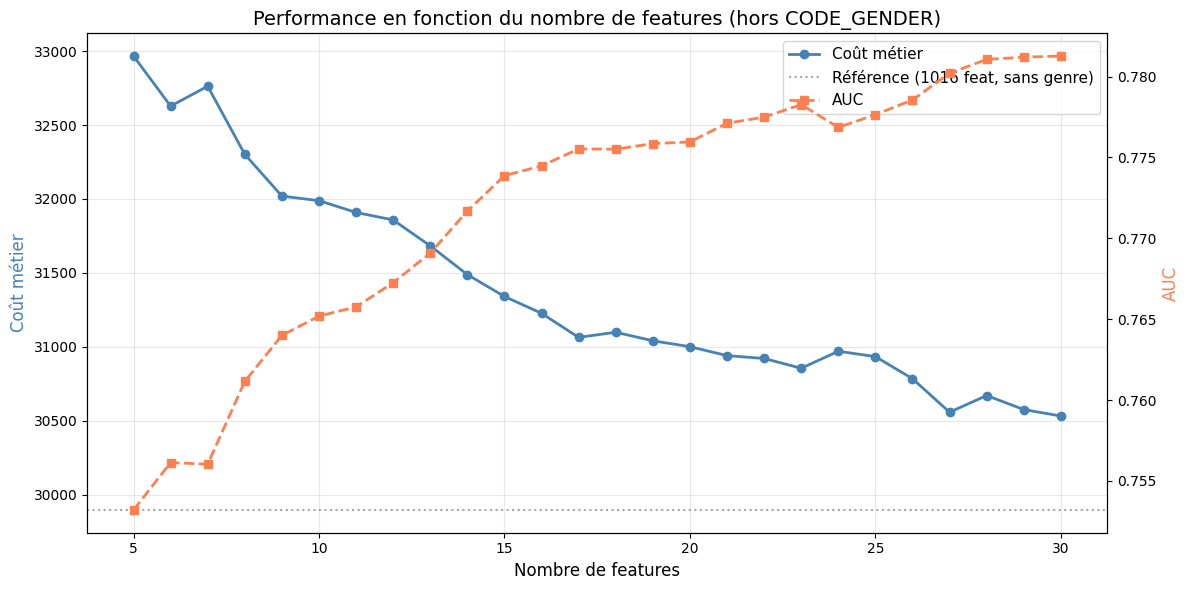

In [41]:
# --- Visualisation ---
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(df_curve['n_features'], df_curve['cout_metier'], 'o-', color='steelblue', linewidth=2, label='Coût métier')
ax1.axhline(y=29898, color='gray', linestyle=':', alpha=0.7, label='Référence (1016 feat, sans genre)')
ax1.set_xlabel('Nombre de features', fontsize=12)
ax1.set_ylabel('Coût métier', fontsize=12, color='steelblue')

ax2 = ax1.twinx()
ax2.plot(df_curve['n_features'], df_curve['auc'], 's--', color='coral', linewidth=2, label='AUC')
ax2.set_ylabel('AUC', fontsize=12, color='coral')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, fontsize=11)

ax1.set_title('Performance en fonction du nombre de features (hors CODE_GENDER)', fontsize=14)
ax1.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('./figures/features_vs_performance.png', dpi=150)
plt.show()

### 10.3. Analyse de la courbe

La courbe montre un point d'inflexion autour de 20 features. Au-delà, les gains
marginaux deviennent très faibles.

| N features | Coût métier | Écart vs modèle complet (sans genre) |
|-----------|-------------|--------------------------------------|
| 10 | 31 989 | +7.0% |
| 15 | 31 341 | +4.8% |
| 20 | 31 002 | +3.7% |
| 25 | 30 935 | +3.5% |
| 30 | 30 533 | +2.1% |

**Choix retenu : 20 features.** Ce nombre offre le meilleur compromis entre
performance (3.7% de dégradation) et simplicité de déploiement.

### 10.4. Log du modèle retenu

In [42]:
# --- Modèle final allégé : 20 features (hors CODE_GENDER) ---
top_20_features = feature_ranking_clean.head(20).index.tolist()
X_light_20 = X[top_20_features]

print("=== 20 features retenues ===\n")
for i, feat in enumerate(top_20_features, 1):
    print(f"  {i:2d}. {feat}")

pipeline_lgbm_light20 = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler()),
    ('classifier', LGBMClassifier(
        **study.best_params,
        is_unbalance=True,
        random_state=42,
        verbose=-1
    ))
])

train_and_log_model(
    pipeline_lgbm_light20, X_light_20, y,
    experiment_name="Projet6_Scoring_Credit",
    run_name="LightGBM_light_20features",
    tags_dict={
        "features": "top20_shap_no_gender",
        "statut": "developpement",
        "Type_modele": "champion_light_production",
        "mlflow.note.content": (
            "Modèle allégé : 20 features SHAP (hors CODE_GENDER). "
            "HP optimisés par Optuna. "
            "Coût métier +3.7% vs modèle complet. "
            "Destiné au déploiement Projet 8."
        )
    },
    step=6
)

=== 20 features retenues ===

   1. EXT_SOURCE_2
   2. EXT_SOURCE_3
   3. EXT_SOURCE_1
   4. BUREAU_BUREAU_DEBT_CREDIT_RATIO_MAX
   5. APP_PAYMENT_RATE
   6. AMT_ANNUITY
   7. DAYS_EMPLOYED
   8. AMT_GOODS_PRICE
   9. INSTAL_INSTAL_DAYS_LATE_MAX
  10. NAME_EDUCATION_TYPE_Higher education
  11. NAME_FAMILY_STATUS_Married
  12. PREV_PREV_APP_CREDIT_RATIO_MEAN
  13. POS_NB_ENTRIES
  14. DAYS_BIRTH
  15. PREV_DAYS_LAST_DUE_1ST_VERSION_MAX
  16. POS_CNT_INSTALMENT_FUTURE_MEAN
  17. INSTAL_INSTAL_PAYMENT_RATIO_MEAN
  18. PREV_NAME_CONTRACT_STATUS_REFUSED_MEAN
  19. BUREAU_DAYS_ENDDATE_FACT_MAX
  20. INSTAL_NB_PAYMENTS
Fold 1/5 - Coût métier : 31385.0000
Fold 2/5 - Coût métier : 30324.0000
Fold 3/5 - Coût métier : 31254.0000
Fold 4/5 - Coût métier : 30484.0000
Fold 5/5 - Coût métier : 31562.0000


2026/03/05 13:38:36 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/03/05 13:38:36 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/03/05 13:38:40 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Registered model 'Credit_Scoring_Model' already exists. Creating a new version of this model...
2026/03/05 13:38:40 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: Credit_Scoring_Model, version 66
Created version '66' of model 'Credit_Sco

Run 'LightGBM_light_20features' terminé — Coût métier : 31001.8000 (±500.3600)
🏃 View run LightGBM_light_20features at: http://127.0.0.1:5000/#/experiments/3/runs/23a74f6be1de441f9cdb4b1223dc9f18
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


### 10.5. Modification de l’alias `champion`

In [43]:
# --- Promouvoir le modèle allégé comme champion ---
client.set_registered_model_alias(
    name="Credit_Scoring_Model",
    alias="champion",
    version="60"
)

client.set_model_version_tag(
    name="Credit_Scoring_Model",
    version="60",
    key="validation_status",
    value="passed"
)

client.set_model_version_tag(
    name="Credit_Scoring_Model",
    version="60",
    key="seuil_optimal",
    value=str(seuil_optimal)
)

# Garder une trace de l'ancien champion
client.set_registered_model_alias(
    name="Credit_Scoring_Model",
    alias="champion_full",
    version=best_version
)

# Vérification
champ = client.get_model_version_by_alias("Credit_Scoring_Model", "champion")
champ_full = client.get_model_version_by_alias("Credit_Scoring_Model", "champion_full")
print(f"Alias 'champion'      = Version {champ.version} (20 features, production)")
print(f"Alias 'champion_full' = Version {champ_full.version} (1016 features, référence)")

Alias 'champion'      = Version 60 (20 features, production)
Alias 'champion_full' = Version 64 (1016 features, référence)


Voici l’interface utilisateur de MLflow avec l’ensemble des runs :

![Vue liste des runs](./images/all_runs.png "Tous les runs de l’expérimentation")

## 11. Conclusion

Ce notebook a couvert l'intégralité du cycle MLOps demandé par le projet :
* **Modélisation** : trois modèles (Régression Logistique, XGBoost, LightGBM) ont été comparés via validation croisée stratifiée sur le dataset enrichi. LightGBM a été retenu pour son meilleur coût métier (30 280).
* **Interprétabilité** : l'analyse de feature importance (built-in, permutation, SHAP) a permis d'identifier les variables les plus influentes à l'échelle globale et individuelle, répondant à l'exigence de transparence du scoring.
* **Optimisation** : Optuna a permis d'affiner les hyperparamètres de LightGBM, et l'optimisation du seuil métier (0.48) a confirmé la bonne calibration du modèle.
* **MLOps** : chaque expérimentation a été tracée dans MLflow, le modèle a été enregistré dans le Model Registry et servi via l'API REST locale.
* **Préparation à la production** : le retrait de `CODE_GENDER` (biais éthique) et la réduction à 20 features offrent un modèle allégé, plus simple à déployer et à monitorer, avec une dégradation maîtrisée de 3,7%.